###### **Import Required Libraries**

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from zipfile import ZipFile
from glob import glob
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
import cv2
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.preprocessing.image import ImageDataGenerator

###### **1.Dataset Download and Extraction**

In [ ]:
def download_and_extract_dataset(zip_url, output_dir, zip_path):
    if not os.path.exists(zip_path):
        !curl -L -o "{zip_path}" {zip_url}
    if not os.path.exists(output_dir):
        with ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(output_dir)

dataset_url = "https://www.kaggle.com/api/v1/datasets/download/masoudnickparvar/brain-tumor-mri-dataset"
zip_path = "/content/brain-tumor-classification-mri.zip"
extracted_path = "/content/braintumordata"

download_and_extract_dataset(dataset_url, extracted_path, zip_path)

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  148M  100  148M    0     0   116M      0  0:00:01  0:00:01 --:--:--  116M


###### **2.Data preparation**

In [ ]:
data_dir = '/content/braintumordata'
train_dir = os.path.join(data_dir, 'Training')
test_dir = os.path.join(data_dir, 'Testing')

###### **3.Exploratory Data Analysis (EDA)**

###### **3.1 Class Labels**

In [ ]:
classes = os.listdir(train_dir)
print("Classes:", classes)

Classes: ['pituitary', 'glioma', 'meningioma', 'notumor']


###### **3.2 Sample Images Per Class**

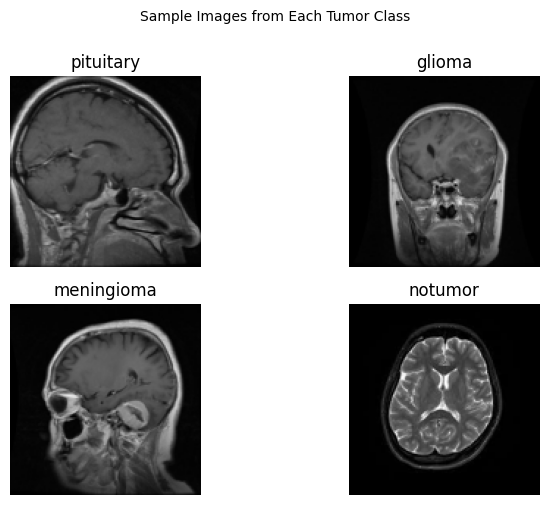

In [ ]:
plt.figure(figsize=(8, 5))

for i, cls in enumerate(classes):
    image_path = glob(os.path.join(train_dir, cls, '*'))[0]
    img = Image.open(image_path).convert('RGB')
    img = img.resize((130, 130))
    plt.subplot(2, 2, i + 1)
    plt.imshow(img)
    plt.title(cls, fontsize=12)
    plt.axis('off')

plt.suptitle("Sample Images from Each Tumor Class", fontsize=10, y=1)
plt.tight_layout()
plt.show()

###### **3.3 Class Distribution (Train vs Test) (Before Balancing)**

In [ ]:
def count_images(directory):
    counts = {}
    for cls in os.listdir(directory):
        counts[cls] = len(os.listdir(os.path.join(directory, cls)))
    return counts

train_counts = count_images(train_dir)
test_counts = count_images(test_dir)

print("Training Counts:", train_counts)
print("Testing Counts:", test_counts)

Training Counts: {'pituitary': 1457, 'glioma': 1321, 'meningioma': 1339, 'notumor': 1595}
Testing Counts: {'pituitary': 300, 'glioma': 300, 'meningioma': 306, 'notumor': 405}


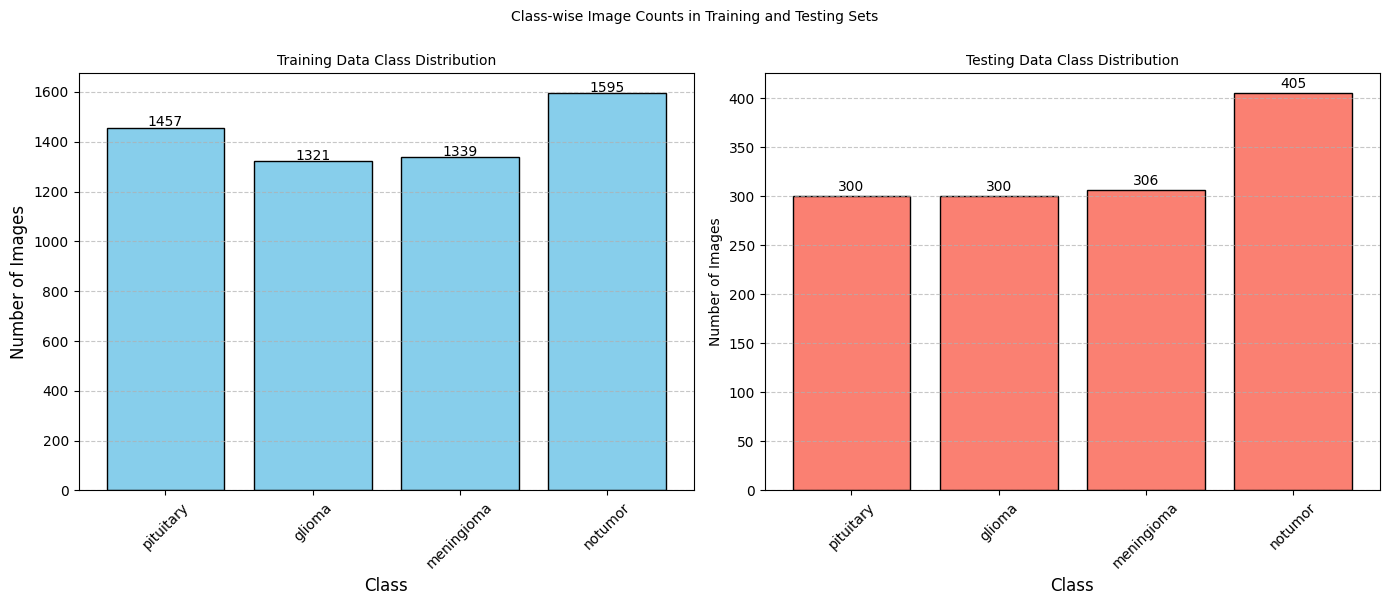

In [ ]:
classes = list(train_counts.keys())
train_values = list(train_counts.values())
test_values = list(test_counts.values())

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].bar(classes, train_values, color='skyblue', edgecolor='black')
ax[0].set_title('Training Data Class Distribution', fontsize=10)
ax[0].set_xlabel('Class', fontsize=12)
ax[0].set_ylabel('Number of Images', fontsize=12)
ax[0].tick_params(axis='x', rotation=45)
ax[0].grid(axis='y', linestyle='--', alpha=0.7)

for i, value in enumerate(train_values):
    ax[0].text(i, value + 5, str(value), ha='center', fontsize=10)

ax[1].bar(classes, test_values, color='salmon', edgecolor='black')
ax[1].set_title('Testing Data Class Distribution', fontsize=10)
ax[1].set_xlabel('Class', fontsize=12)
ax[1].set_ylabel('Number of Images', fontsize=10)
ax[1].tick_params(axis='x', rotation=45)
ax[1].grid(axis='y', linestyle='--', alpha=0.7)

for i, value in enumerate(test_values):
    ax[1].text(i, value + 5, str(value), ha='center', fontsize=10)

plt.suptitle("Class-wise Image Counts in Training and Testing Sets", fontsize=10, y=1)
plt.tight_layout()
plt.show()


###### **3.4 Image Sizes distribution**

In [ ]:
def analyze_image_properties(directory):
    sizes = []
    channels = []
    for cls in os.listdir(directory):
        class_path = os.path.join(directory, cls)
        for img_file in os.listdir(class_path):
            img_path = os.path.join(class_path, img_file)
            try:
                with Image.open(img_path) as img:
                    sizes.append(img.size)
                    channels.append(img.mode)
            except:
                print(f"Could not open image: {img_path}")
    return sizes, channels

train_sizes, train_channels = analyze_image_properties(train_dir)
test_sizes, test_channels = analyze_image_properties(test_dir)

print("Training Image Properties:")
print("  Unique sizes:", Counter(train_sizes).most_common(5)) # Show top 5 most common sizes
print("  Unique channels:", Counter(train_channels))

print("\nTesting Image Properties:")
print("  Unique sizes:", Counter(test_sizes).most_common(5)) # Show top 5 most common sizes
print("  Unique channels:", Counter(test_channels))

Training Image Properties:
  Unique sizes: [((512, 512), 3955), ((225, 225), 268), ((630, 630), 77), ((236, 236), 53), ((201, 251), 43)]
  Unique channels: Counter({'RGB': 3236, 'L': 2472, 'RGBA': 3, 'P': 1})

Testing Image Properties:
  Unique sizes: [((512, 512), 787), ((225, 225), 64), ((236, 236), 28), ((227, 222), 17), ((201, 251), 15)]
  Unique channels: Counter({'RGB': 690, 'L': 621})


/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


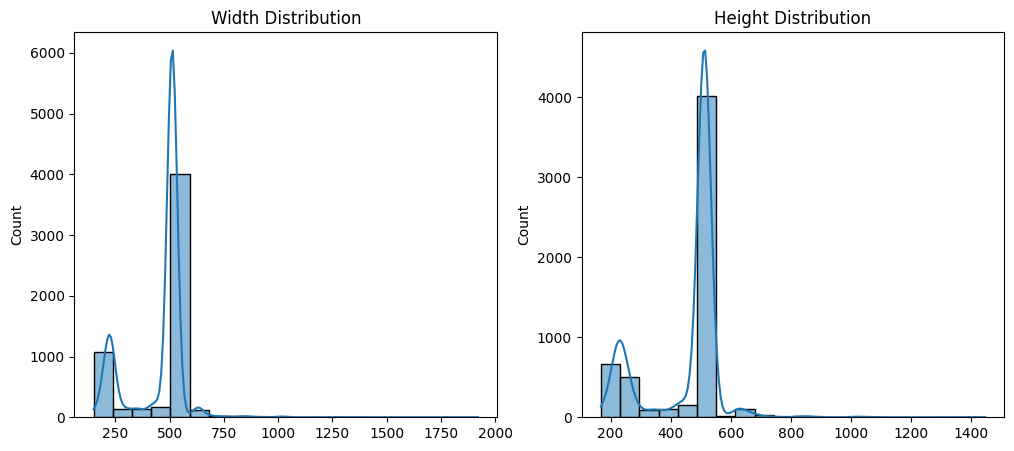

In [ ]:
# Image size distribution
widths, heights = zip(*train_sizes)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(widths, bins=20, kde=True)
plt.title("Width Distribution")

plt.subplot(1, 2, 2)
sns.histplot(heights, bins=20, kde=True)
plt.title("Height Distribution")
plt.show()

###### **3.5 Data Augmentation Visualization (4 per class)**

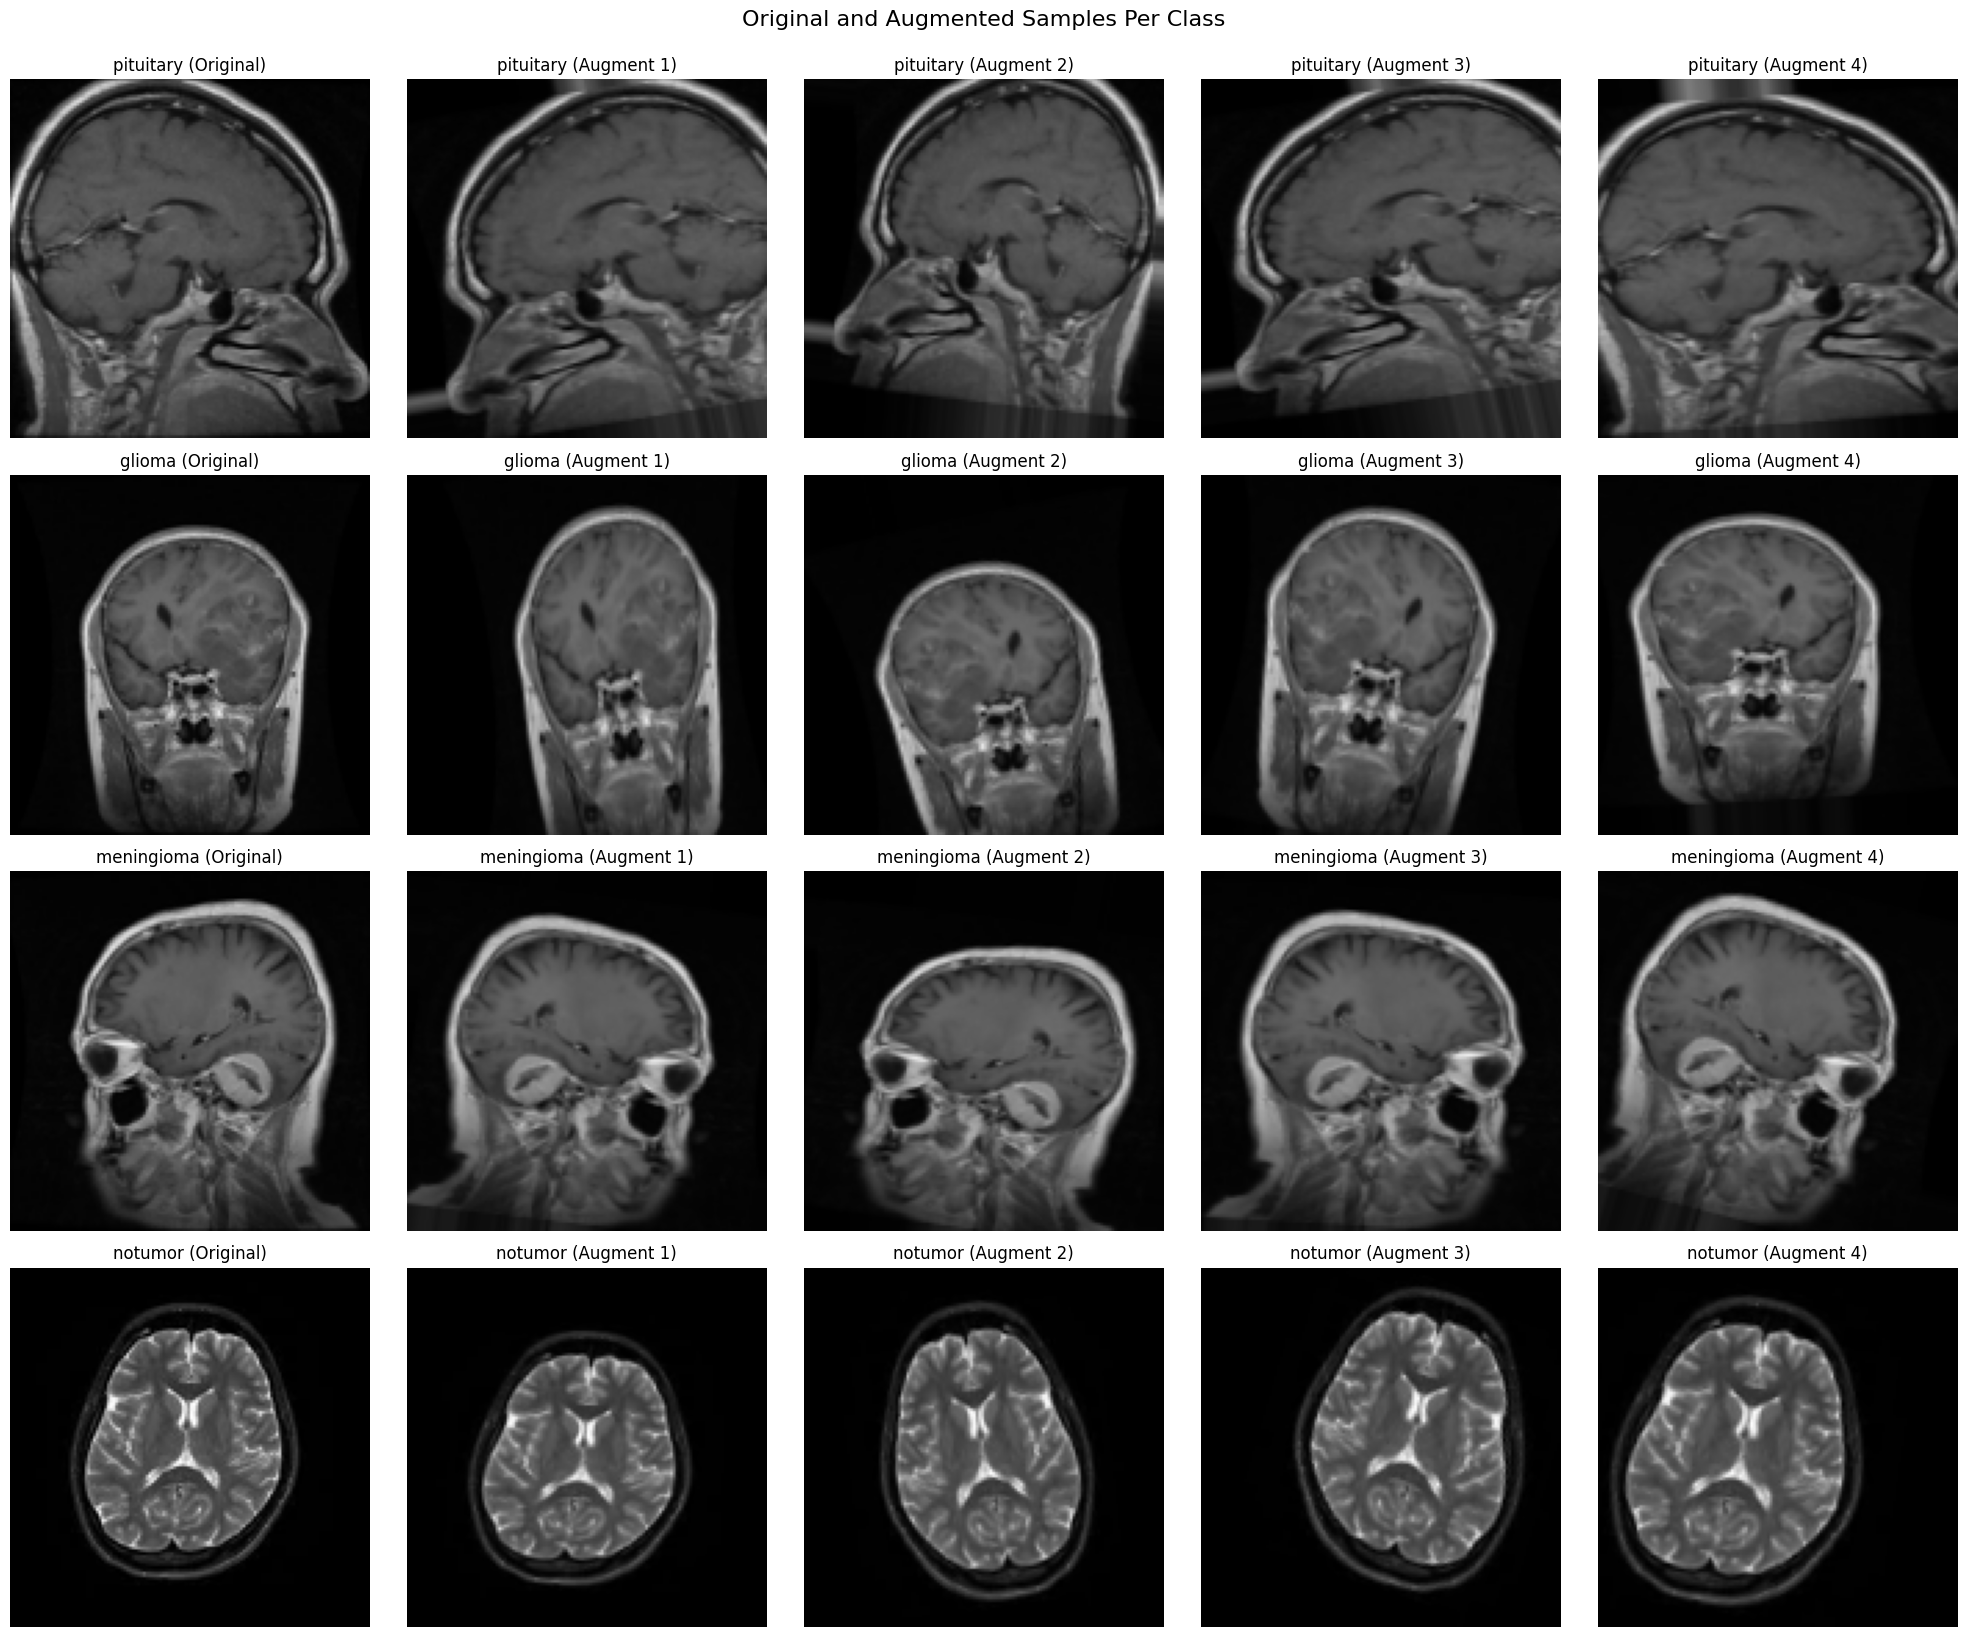

In [ ]:
def visualize_multiple_augmented_images(train_dir, classes):
    fig, axes = plt.subplots(len(classes), 5, figsize=(20, 4 * len(classes)))
    for i, cls in enumerate(classes):
        img_path = glob(os.path.join(train_dir, cls, '*'))[0]
        img = Image.open(img_path).convert('RGB').resize((130, 130))
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f"{cls} (Original)")
        axes[i, 0].axis('off')
        img_array = np.expand_dims(np.array(img), axis=0)

        aug_gen = ImageDataGenerator(
            rescale=1./255,
            rotation_range=20,
            zoom_range=0.15,
            width_shift_range=0.1,
            height_shift_range=0.1,
            shear_range=0.15,
            horizontal_flip=True,
            fill_mode="nearest"
        )

        gen = aug_gen.flow(img_array, batch_size=1)
        for j in range(1, 5):
            batch = next(gen)[0]
            axes[i, j].imshow(batch)
            axes[i, j].set_title(f"{cls} (Augment {j})")
            axes[i, j].axis('off')

    plt.tight_layout()
    plt.suptitle("Original and Augmented Samples Per Class", fontsize=16, y=1.02)
    plt.show()

visualize_multiple_augmented_images(train_dir, classes)

###### **4. Data Balancing - Random Sampling**

In [ ]:
import pandas as pd
import numpy as np
import random
from glob import glob
import os

def create_balanced_dataframe(train_dir):
    image_paths = []
    labels = []

    for cls in os.listdir(train_dir):
        class_path = os.path.join(train_dir, cls)
        imgs = glob(os.path.join(class_path, '*'))
        image_paths.extend(imgs)
        labels.extend([cls] * len(imgs))

    df = pd.DataFrame({'image_path': image_paths, 'label': labels})
    max_count = df['label'].value_counts().max()

    balanced_dfs = []
    for label in df['label'].unique():
        class_df = df[df['label'] == label]
        resampled_df = class_df.sample(max_count, replace=True, random_state=42)
        balanced_dfs.append(resampled_df)

    balanced_df = pd.concat(balanced_dfs).reset_index(drop=True)
    return balanced_df

balanced_df = create_balanced_dataframe(train_dir)
print(balanced_df['label'].value_counts())


label
pituitary     1595
glioma        1595
meningioma    1595
notumor       1595
Name: count, dtype: int64


###### **4.1 Class Distribution Before and After Balancing**

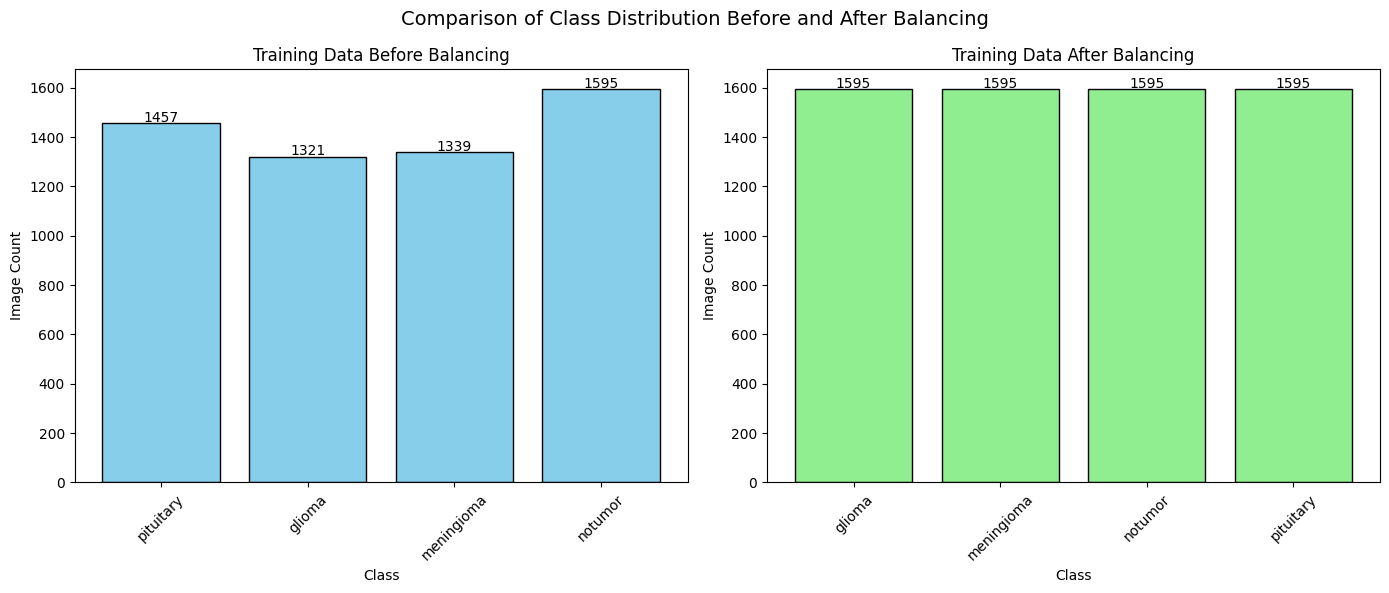

In [ ]:
import matplotlib.pyplot as plt

# Before balancing
original_counts = count_images(train_dir)  # This function is already defined
original_labels = list(original_counts.keys())
original_values = list(original_counts.values())

# After balancing (from balanced_df)
balanced_counts = balanced_df['label'].value_counts().sort_index()
balanced_labels = balanced_counts.index.tolist()
balanced_values = balanced_counts.values.tolist()

# Plotting
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Original
ax[0].bar(original_labels, original_values, color='skyblue', edgecolor='black')
ax[0].set_title('Training Data Before Balancing')
ax[0].set_xlabel('Class')
ax[0].set_ylabel('Image Count')
ax[0].tick_params(axis='x', rotation=45)
for i, v in enumerate(original_values):
    ax[0].text(i, v + 5, str(v), ha='center', fontsize=10)

# Balanced
ax[1].bar(balanced_labels, balanced_values, color='lightgreen', edgecolor='black')
ax[1].set_title('Training Data After Balancing')
ax[1].set_xlabel('Class')
ax[1].set_ylabel('Image Count')
ax[1].tick_params(axis='x', rotation=45)
for i, v in enumerate(balanced_values):
    ax[1].text(i, v + 5, str(v), ha='center', fontsize=10)

plt.suptitle("Comparison of Class Distribution Before and After Balancing", fontsize=14)
plt.tight_layout()
plt.show()


###### **5. Train-Validation Split**

In [ ]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    balanced_df,
    test_size=0.2,
    stratify=balanced_df['label'],
    random_state=42
)

print("Train size:", len(train_df))
print("Validation size:", len(val_df))


Train size: 5104
Validation size: 1276


##### **5.1 Class Distribution (Train, Validation, Test)**

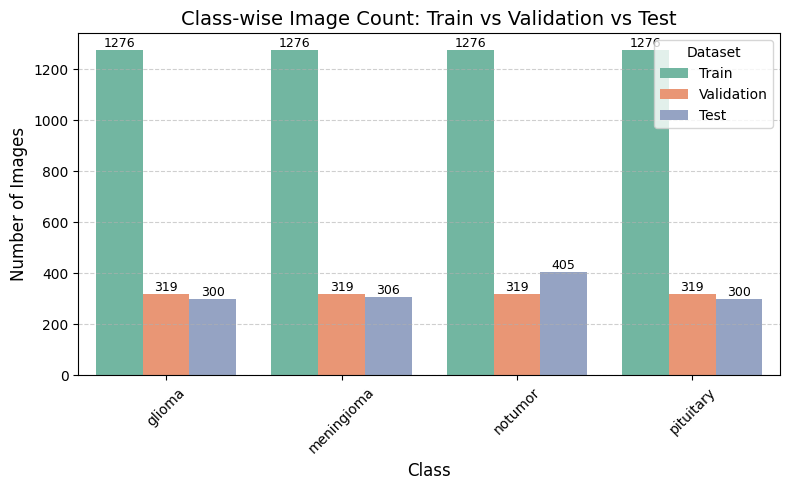

In [ ]:
# Train / Validation counts
train_counts = train_df['label'].value_counts().sort_index()
val_counts = val_df['label'].value_counts().sort_index()

# Test counts (from generator directly)
test_counts = pd.Series(test_generator.classes).value_counts().sort_index()
test_counts.index = [list(test_generator.class_indices.keys())[i] for i in test_counts.index]

# Combine into one DataFrame
distribution_df = pd.DataFrame({
    'Class': train_counts.index,
    'Train': train_counts.values,
    'Validation': val_counts.values,
    'Test': test_counts.values
})

# Melt into long format for Seaborn
distribution_df = distribution_df.melt(id_vars='Class', var_name='Dataset', value_name='Count')

# Plot
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=distribution_df, x='Class', y='Count', hue='Dataset', palette='Set2')

# Annotate counts on top of bars
for p in ax.patches:
    height = int(p.get_height())
    ax.annotate(f'{height}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=9, color='black')

plt.title('Class-wise Image Count: Train vs Validation vs Test', fontsize=14)
plt.xlabel('Class', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


###### **6. Image Data Generators**

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_HEIGHT = 130
IMG_WIDTH = 130
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    horizontal_flip=True,
    fill_mode="nearest"
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='image_path',
    y_col='label',
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

validation_generator = train_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='image_path',
    y_col='label',
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print("\nTrain Generator class indices:", train_generator.class_indices)
print("Validation Generator class indices:", validation_generator.class_indices)
print("Test Generator class indices:", test_generator.class_indices)


Found 5104 validated image filenames belonging to 4 classes.
Found 1276 validated image filenames belonging to 4 classes.
Found 1311 images belonging to 4 classes.

Train Generator class indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Validation Generator class indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Test Generator class indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


###### **7. CNN Model Building**

In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix

# Build the model
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(classes), activation='softmax') # Output layer with number of classes
])


# Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy', # Use categorical_crossentropy for multi-class
              metrics=['accuracy'])

model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 62, 62, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 31, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 29, 29, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    12,845,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,940,868 (49.37 MB)

 Trainable params: 12,940,868 (49.37 MB)

 Non-trainable params: 0 (0.00 B)

###### **7.1 Training**

In [ ]:
# Train the model
EPOCHS = 100

history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // BATCH_SIZE
)


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 43s 232ms/step - accuracy: 0.4292 - loss: 1.2517 - val_accuracy: 0.6995 - val_loss: 0.7104
Epoch 2/100
  1/159 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.5625 - loss: 0.7859

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:107: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


159/159 ━━━━━━━━━━━━━━━━━━━━ 10s 62ms/step - accuracy: 0.5625 - loss: 0.7859 - val_accuracy: 0.7332 - val_loss: 0.6888
Epoch 3/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 67s 225ms/step - accuracy: 0.6970 - loss: 0.7431 - val_accuracy: 0.7652 - val_loss: 0.5806
Epoch 4/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step - accuracy: 0.7812 - loss: 0.5073 - val_accuracy: 0.7260 - val_loss: 0.6501
Epoch 5/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 36s 223ms/step - accuracy: 0.7299 - loss: 0.6655 - val_accuracy: 0.7668 - val_loss: 0.5902
Epoch 6/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 10s 65ms/step - accuracy: 0.8125 - loss: 0.5401 - val_accuracy: 0.7564 - val_loss: 0.6183
Epoch 7/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 74s 240ms/step - accuracy: 0.7824 - loss: 0.5488 - val_accuracy: 0.7973 - val_loss: 0.4619
Epoch 8/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - accuracy: 0.8438 - loss: 0.4761 - val_accuracy: 0.7989 - val_loss: 0.4831
Epoch 9/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 34s 214ms/step - accuracy: 0.7862 - loss: 0.5346 - va

###### **7.2 Training, validation Accuracy and Loss plots**

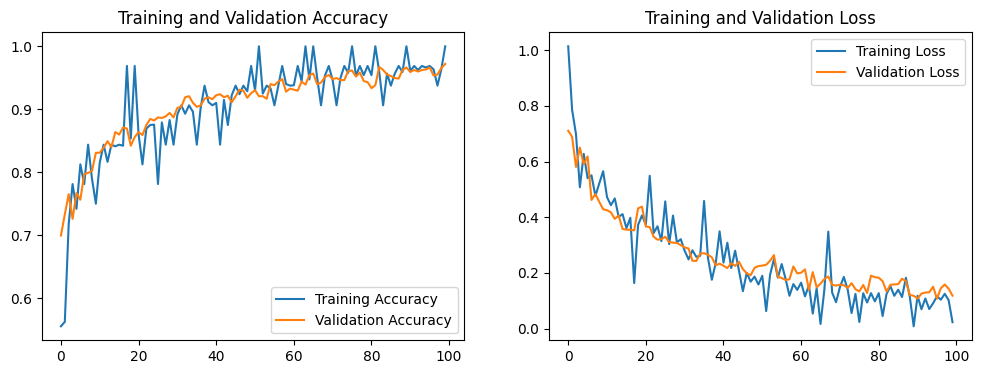

In [ ]:
# Plot training history
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(EPOCHS)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

###### **8.Model Evaluation**

In [ ]:
# Evaluate on test data
print("\nEvaluating on test data...")
loss, accuracy = model.evaluate(test_generator)

print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

test_generator.reset()
predictions = model.predict(test_generator)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())


Evaluating on test data...
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - accuracy: 0.8636 - loss: 0.4309
Test Loss: 0.2501
Test Accuracy: 0.9199
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step


###### **8.1 classification Report**

In [ ]:
# Classification Report
print("\nClassification Report:")
print(classification_report(true_classes, predicted_classes, target_names=class_labels))


Classification Report:
              precision    recall  f1-score   support

      glioma       0.98      0.80      0.88       300
  meningioma       0.88      0.88      0.88       306
     notumor       0.90      1.00      0.95       405
   pituitary       0.94      0.98      0.96       300

    accuracy                           0.92      1311
   macro avg       0.93      0.91      0.92      1311
weighted avg       0.92      0.92      0.92      1311



###### **8.2 confusion matrix**

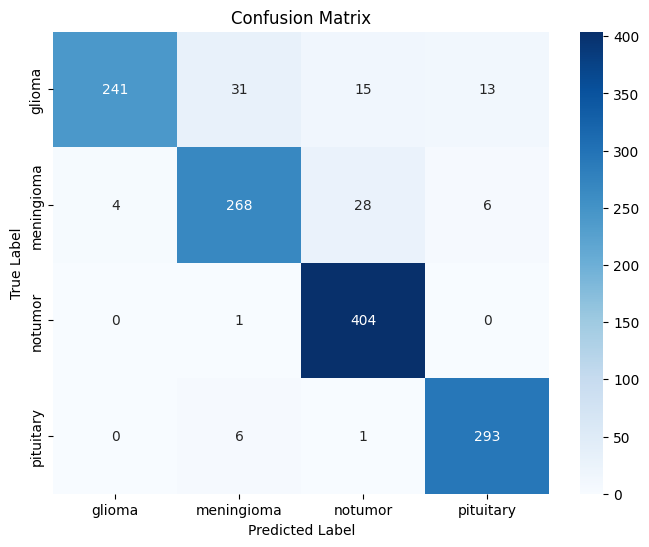

In [ ]:
# Confusion Matrix
cm = confusion_matrix(true_classes, predicted_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

#### **9. Transfer Learning**

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.9/400.9 kB 27.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.4/247.4 kB 23.0 MB/s eta 0:00:00


##### **9.1  Imports**

In [ ]:
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score
from tensorflow.keras import backend as K
import optuna

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

##### **9.2 Data Preparation (for Transfer Models)**

In [ ]:
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    horizontal_flip=True,
    fill_mode="nearest"
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='image_path',
    y_col='label',
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

validation_generator = train_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='image_path',
    y_col='label',
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

num_classes = len(train_generator.class_indices)

print("\n Class Indices:")
print("Train:", train_generator.class_indices)
print("Val:", validation_generator.class_indices)
print("Test:", test_generator.class_indices)



Found 5104 validated image filenames belonging to 4 classes.
Found 1276 validated image filenames belonging to 4 classes.
Found 1311 images belonging to 4 classes.

Class Indices:
Train: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Val: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Test: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


##### **9.3 Transfer learning Model Builder & Compiler**

In [ ]:
def build_transfer_model(base_model, num_classes, dropout_rate):
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dropout(dropout_rate)(x)
    preds = Dense(num_classes, activation='softmax')(x)
    return Model(inputs=base_model.input, outputs=preds)


def compile_model(model, optimizer_choice="adam", lr=1e-4):
    if optimizer_choice == "adam":
        opt = Adam(learning_rate=lr)
    elif optimizer_choice == "adamw":
        opt = tf.keras.optimizers.AdamW(learning_rate=lr)
    else:
        opt = tf.keras.optimizers.RMSprop(learning_rate=lr)

    model.compile(optimizer=opt,
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

##### **9.4 Callbacks**

In [ ]:
def get_callbacks():
    return [
        EarlyStopping(patience=5, restore_best_weights=True, monitor="val_loss"),
        ReduceLROnPlateau(factor=0.2, patience=2, verbose=1, monitor="val_loss"),
    ]

##### **9.5 Training Utility**

In [ ]:
def train_model(model, train_gen, val_gen, epochs=50):
    history = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=epochs,
        callbacks=get_callbacks(),
        verbose=1
    )
    return history


##### **9.6 Training Curve Plot Function**

In [ ]:
def plot_training_curves(history, model_name="Model"):
    acc = history.history["accuracy"]
    val_acc = history.history["val_accuracy"]
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]
    epochs_range = range(1, len(acc)+1)

    plt.figure(figsize=(12,4))

    # Accuracy
    plt.subplot(1,2,1)
    plt.plot(epochs_range, acc, label="Train Accuracy")
    plt.plot(epochs_range, val_acc, label="Val Accuracy")
    plt.xlabel("Epochs"); plt.ylabel("Accuracy")
    plt.title(f"{model_name} Accuracy")
    plt.legend(); plt.grid(alpha=0.3)

    # Loss
    plt.subplot(1,2,2)
    plt.plot(epochs_range, loss, label="Train Loss")
    plt.plot(epochs_range, val_loss, label="Val Loss")
    plt.xlabel("Epochs"); plt.ylabel("Loss")
    plt.title(f"{model_name} Loss")
    plt.legend(); plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


##### **9.7 Evaluation Utility**

In [ ]:
def evaluate_model(model, test_gen, model_name="Model"):
    test_loss, test_acc = model.evaluate(test_gen, verbose=1)
    print(f"\n {model_name} Test Accuracy: {test_acc:.4f}")
    print(f" {model_name} Test Loss: {test_loss:.4f}")

    # Predictions
    y_pred = np.argmax(model.predict(test_gen), axis=1)
    y_true = test_gen.classes
    labels = list(test_gen.class_indices.keys())

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=labels))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

##### **10. Hyperparameter Tuning (Optuna)**

##### **10.1 Objective Function**

In [ ]:
def objective(trial):
    K.clear_session()

    lr = trial.suggest_loguniform("lr", 1e-5, 1e-3)
    dropout_rate = trial.suggest_uniform("dropout", 0.4, 0.6)
    optimizer_choice = trial.suggest_categorical("optimizer", ["adam", "adamw"])

    base_model = tf.keras.applications.EfficientNetB0(
        weights="imagenet", include_top=False, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
    )

    model = build_transfer_model(base_model, num_classes, dropout_rate)
    model = compile_model(model, optimizer_choice, lr)

    history = model.fit(
        train_generator,
        validation_data=validation_generator,
        epochs=5,
        verbose=1,
        callbacks=[EarlyStopping(patience=2, restore_best_weights=True, monitor="val_loss")]
    )

    val_acc = max(history.history["val_accuracy"])
    return val_acc

##### **10.2 Run Optuna Study**

In [ ]:
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10)

[I 2025-08-31 04:30:49,870] A new study created in memory with name: no-name-3259d0b2-9963-4b82-bcac-d334e176e58a
/tmp/ipykernel_36/2639949631.py:8: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  lr = trial.suggest_loguniform("lr", 1e-5, 1e-3)
/tmp/ipykernel_36/2639949631.py:9: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float instead.
  dropout_rate = trial.suggest_uniform("dropout", 0.4, 0.6)
Epoch 1/5
I0000 00:00:1756614708.798666     157 service.cc:148] XLA service 0x794200615e60 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1756614708.800503     157 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1756614

##### **10.3 Best Hyperparameters**

In [ ]:
print("Best Trial:")
trial = study.best_trial
print(f"  Validation Accuracy: {trial.value:.4f}")
print("  Best Hyperparameters:", trial.params)

Best Trial:
  Validation Accuracy: 0.4569
  Best Hyperparameters: {'lr': 1.4478983754170569e-05, 'dropout': 0.5510600612221351, 'optimizer': 'adamw'}


In [ ]:
best_params = study.best_trial.params
final_lr = best_params["lr"]
final_dropout = best_params["dropout"]
final_optimizer = best_params["optimizer"]

##### **11. Final Model Training (EfficientNetB0)**

In [ ]:
base_final = tf.keras.applications.EfficientNetB0(weights="imagenet", include_top=False,
                                                  input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
final_model = build_transfer_model(base_final, num_classes, final_dropout)
final_model = compile_model(final_model, final_optimizer, final_lr)

In [ ]:
history_final = train_model(final_model, train_generator, validation_generator, epochs=50)


Epoch 1/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 151s 434ms/step - accuracy: 0.3200 - loss: 1.4399 - val_accuracy: 0.3002 - val_loss: 1.4514 - learning_rate: 1.4479e-05
Epoch 2/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 29s 182ms/step - accuracy: 0.5967 - loss: 1.0095 - val_accuracy: 0.2547 - val_loss: 1.3970 - learning_rate: 1.4479e-05
Epoch 3/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 29s 183ms/step - accuracy: 0.7232 - loss: 0.7533 - val_accuracy: 0.2500 - val_loss: 1.6617 - learning_rate: 1.4479e-05
Epoch 4/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 30s 184ms/step - accuracy: 0.7665 - loss: 0.6406 - val_accuracy: 0.2696 - val_loss: 1.3609 - learning_rate: 1.4479e-05
Epoch 5/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 30s 186ms/step - accuracy: 0.8102 - loss: 0.5326 - val_accuracy: 0.3323 - val_loss: 1.3474 - learning_rate: 1.4479e-05
Epoch 6/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 30s 185ms/step - accuracy: 0.8345 - loss: 0.4627 - val_accuracy: 0.7892 - val_loss: 0.6410 - learning_rate: 1.4479e-05
Epoch 7/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 29s 1

###### **11.1 Training & Curves**


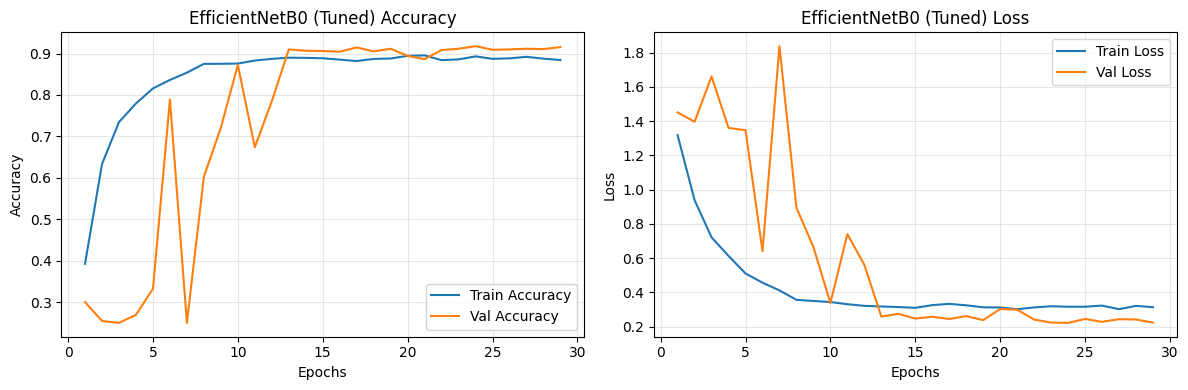

In [ ]:
plot_training_curves(history_final, "EfficientNetB0 (Tuned)")

###### **11.2 Test Evaluation**

41/41 ━━━━━━━━━━━━━━━━━━━━ 6s 155ms/step - accuracy: 0.7740 - loss: 0.5731

 EfficientNetB0 (Tuned) Test Accuracy: 0.8467
 EfficientNetB0 (Tuned) Test Loss: 0.4107
41/41 ━━━━━━━━━━━━━━━━━━━━ 14s 193ms/step

Classification Report:
              precision    recall  f1-score   support

      glioma       0.91      0.78      0.84       300
  meningioma       0.84      0.60      0.70       306
     notumor       0.86      0.97      0.91       405
   pituitary       0.79      0.99      0.88       300

    accuracy                           0.85      1311
   macro avg       0.85      0.84      0.83      1311
weighted avg       0.85      0.85      0.84      1311




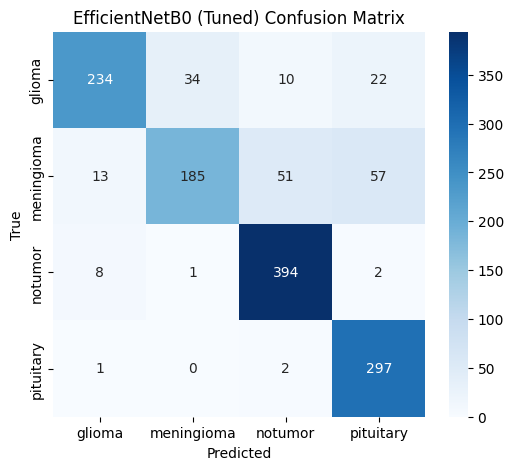

In [ ]:
evaluate_model(final_model, test_generator, "EfficientNetB0 (Tuned)")

###### **12. ResNet50 Training & Evaluation**

In [ ]:
base_resnet = tf.keras.applications.ResNet50(
    weights="imagenet", include_top=False, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)

resnet_model = build_transfer_model(base_resnet, num_classes, final_dropout)
resnet_model = compile_model(resnet_model, final_optimizer, final_lr)

history_resnet = train_model(resnet_model, train_generator, validation_generator,
                             epochs=50)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 133s 373ms/step - accuracy: 0.4862 - loss: 1.4039 - val_accuracy: 0.2500 - val_loss: 2.0437 - learning_rate: 1.4479e-05
Epoch 2/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 32s 197ms/step - accuracy: 0.8203 - loss: 0.4866 - val_accuracy: 0.2727 - val_loss: 1.6953 - learning_rate: 1.4479e-05
Epoch 3/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 32s 196ms/step - accuracy: 0.8872 - loss: 0.3293 - val_accuracy: 0.3644 - val_loss: 1.4203 - learning_rate: 1.4479e-05
Epoch 4/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 32s 201ms/step - accuracy: 0.9124 - loss: 0.2474 - val_accuracy: 0.4263 - val_loss: 1.2453 - learning_rate: 1.4479e-05
Epoch 5/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 32s 197ms/step - accuracy: 0.9210 - loss: 0.2146 - val_accuracy: 0.5180 - val_loss: 1.1362 - learning_rate: 1.4479e-05
Epoch 6/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 31s 194ms/step - accuracy: 0.9431 - loss: 0.1588 - val_accuracy: 0.5815 - val_loss: 1.1333 - learning_rate: 1.447

###### **12.1 Training & Curves**

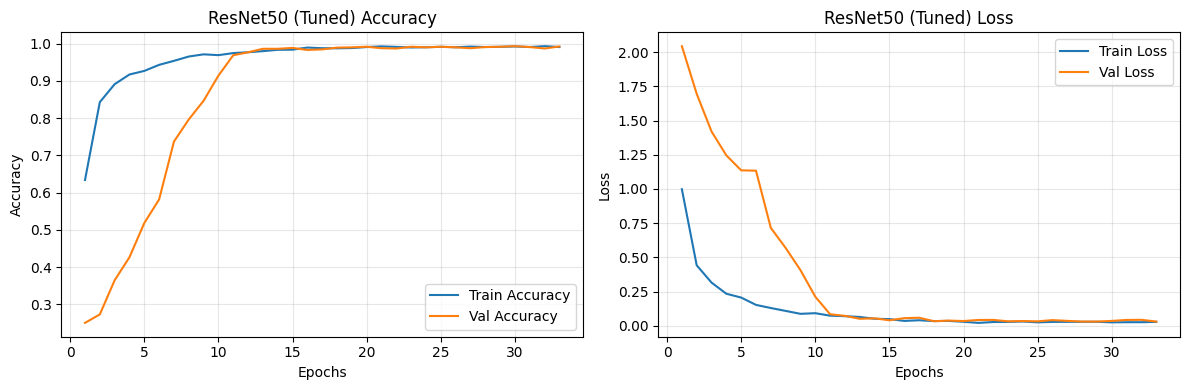

In [ ]:
plot_training_curves(history_resnet, "ResNet50 (Tuned)")

###### **12.2 Test Evaluation**

41/41 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - accuracy: 0.9520 - loss: 0.1681

 ResNet50 (Tuned) Test Accuracy: 0.9619
 ResNet50 (Tuned) Test Loss: 0.1434
41/41 ━━━━━━━━━━━━━━━━━━━━ 10s 143ms/step

Classification Report:
              precision    recall  f1-score   support

      glioma       0.97      0.96      0.96       300
  meningioma       0.97      0.89      0.93       306
     notumor       0.98      1.00      0.99       405
   pituitary       0.93      0.99      0.96       300

    accuracy                           0.96      1311
   macro avg       0.96      0.96      0.96      1311
weighted avg       0.96      0.96      0.96      1311



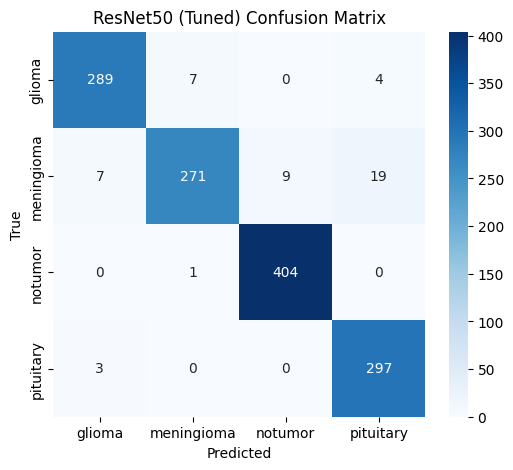

In [ ]:
evaluate_model(resnet_model, test_generator, "ResNet50 (Tuned)")

###### **13. Xception Training & Evaluation**

In [ ]:
base_xception = tf.keras.applications.Xception(
    weights="imagenet", include_top=False, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)

xception_model = build_transfer_model(base_xception, num_classes, final_dropout)
xception_model = compile_model(xception_model, final_optimizer, final_lr)


83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
history_xception = train_model(xception_model, train_generator, validation_generator,
                               epochs=50)


Epoch 1/50


E0000 00:00:1756619733.414018     156 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1756619733.561048     156 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1756619734.052567     156 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1756619734.188043     156 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


 42/160 ━━━━━━━━━━━━━━━━━━━━ 18s 155ms/step - accuracy: 0.2691 - loss: 1.4243

E0000 00:00:1756619756.134306     156 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1756619756.274809     156 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


160/160 ━━━━━━━━━━━━━━━━━━━━ 110s 333ms/step - accuracy: 0.4016 - loss: 1.2867 - val_accuracy: 0.6567 - val_loss: 0.8590 - learning_rate: 1.4479e-05
Epoch 2/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 31s 194ms/step - accuracy: 0.7496 - loss: 0.7074 - val_accuracy: 0.7649 - val_loss: 0.6544 - learning_rate: 1.4479e-05
Epoch 3/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 31s 192ms/step - accuracy: 0.8450 - loss: 0.4358 - val_accuracy: 0.8174 - val_loss: 0.5307 - learning_rate: 1.4479e-05
Epoch 4/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 31s 192ms/step - accuracy: 0.8814 - loss: 0.3280 - val_accuracy: 0.9052 - val_loss: 0.2736 - learning_rate: 1.4479e-05
Epoch 5/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 32s 198ms/step - accuracy: 0.8959 - loss: 0.2834 - val_accuracy: 0.9318 - val_loss: 0.1896 - learning_rate: 1.4479e-05
Epoch 6/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 31s 194ms/step - accuracy: 0.9258 - loss: 0.2136 - val_accuracy: 0.9538 - val_loss: 0.1418 - learning_rate: 1.4479e-05
Epoch 7/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 31s 192ms/step -

###### **13.1 Training & Curves**

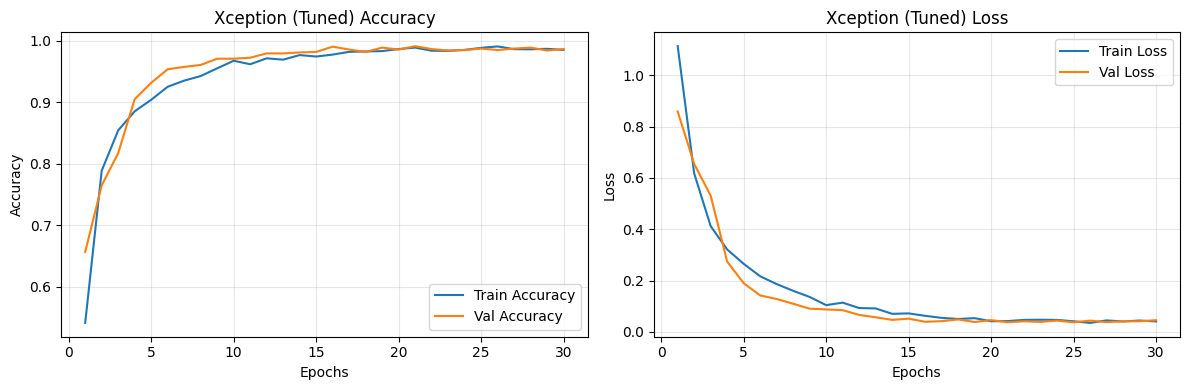

In [ ]:
plot_training_curves(history_xception, "Xception (Tuned)")

###### **13.2 Test Evaluation**

41/41 ━━━━━━━━━━━━━━━━━━━━ 5s 127ms/step - accuracy: 0.9599 - loss: 0.1282

 Xception (Tuned) Test Accuracy: 0.9703
 Xception (Tuned) Test Loss: 0.0973
41/41 ━━━━━━━━━━━━━━━━━━━━ 8s 115ms/step

Classification Report:
              precision    recall  f1-score   support

      glioma       0.98      0.97      0.97       300
  meningioma       0.97      0.92      0.94       306
     notumor       0.98      1.00      0.99       405
   pituitary       0.95      0.99      0.97       300

    accuracy                           0.97      1311
   macro avg       0.97      0.97      0.97      1311
weighted avg       0.97      0.97      0.97      1311



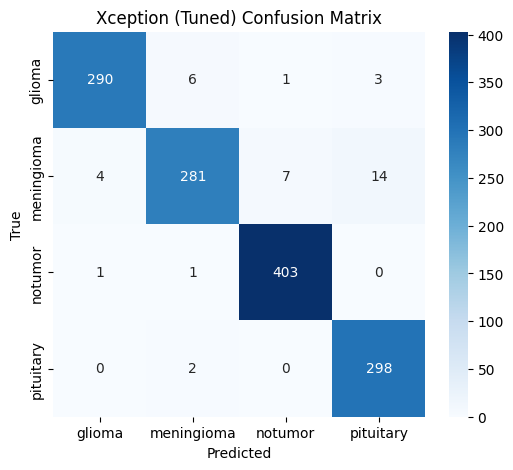

In [ ]:
evaluate_model(xception_model, test_generator, "Xception (Tuned)")

###### **14. Comparative Analysis of Models**

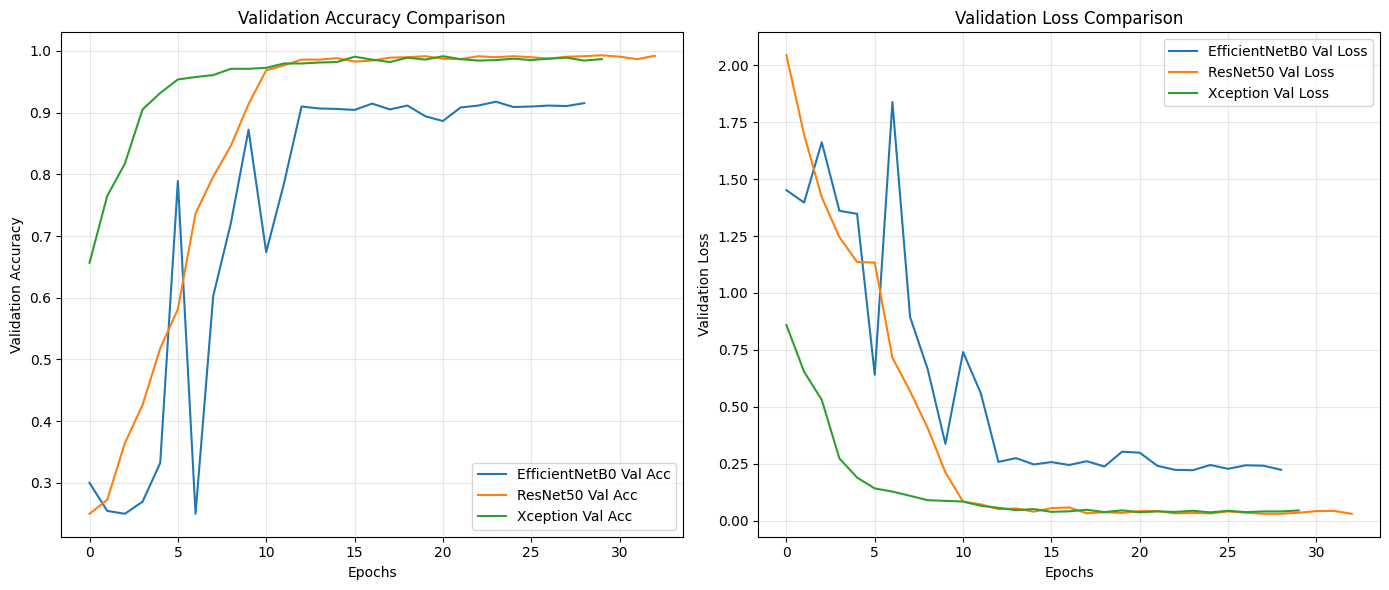

In [ ]:
def compare_histories(histories, model_names):
    plt.figure(figsize=(14,6))

    plt.subplot(1,2,1)
    for history, name in zip(histories, model_names):
        plt.plot(history.history["val_accuracy"], label=f"{name} Val Acc")
    plt.xlabel("Epochs"); plt.ylabel("Validation Accuracy")
    plt.title("Validation Accuracy Comparison")
    plt.legend(); plt.grid(alpha=0.3)

    plt.subplot(1,2,2)
    for history, name in zip(histories, model_names):
        plt.plot(history.history["val_loss"], label=f"{name} Val Loss")
    plt.xlabel("Epochs"); plt.ylabel("Validation Loss")
    plt.title("Validation Loss Comparison")
    plt.legend(); plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

compare_histories(
    [history_final, history_resnet, history_xception],
    ["EfficientNetB0", "ResNet50", "Xception"]
)

###### **15. Ensemble Learning**

###### **15.1 Dynamic Weighted Ensemble (Val Accuracy Based)**

 Validation Accuracies: [0.9858934283256531, 0.9913793206214905]
 Dynamic Weights (based on validation accuracy): [0.49861276 0.50138724]

 Classification Report (Dynamic Weighted Ensemble - Val Acc):
              precision    recall  f1-score   support

      glioma       0.99      0.97      0.98       300
  meningioma       0.98      0.92      0.95       306
     notumor       0.98      1.00      0.99       405
   pituitary       0.95      1.00      0.97       300

    accuracy                           0.97      1311
   macro avg       0.97      0.97      0.97      1311
weighted avg       0.97      0.97      0.97      1311




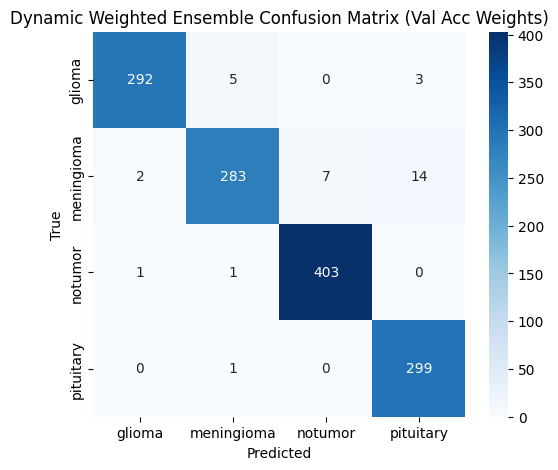

In [ ]:
def get_val_accuracy(model, val_gen):
    loss, acc = model.evaluate(val_gen, verbose=0)
    return acc

models = [xception_model, resnet_model]
val_accuracies = [get_val_accuracy(m, validation_generator) for m in models]

print(" Validation Accuracies:", val_accuracies)

weights = np.array(val_accuracies) / np.sum(val_accuracies)
print(" Dynamic Weights (based on validation accuracy):", weights)


def weighted_ensemble_predictions(models, weights, test_gen):
    preds = [m.predict(test_gen, verbose=0) for m in models]

    weighted_preds = np.zeros_like(preds[0])
    for p, w in zip(preds, weights):
        weighted_preds += w * p

    y_pred = np.argmax(weighted_preds, axis=1)
    return y_pred, weighted_preds


y_pred, weighted_preds = weighted_ensemble_predictions(models, weights, test_generator)

y_true = test_generator.classes
labels = list(test_generator.class_indices.keys())

print("\n Classification Report (Dynamic Weighted Ensemble - Val Acc):")
print(classification_report(y_true, y_pred, target_names=labels))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Dynamic Weighted Ensemble Confusion Matrix (Val Acc Weights)")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.show()

###### **15.2 ROC Curves (Models vs Ensemble)**

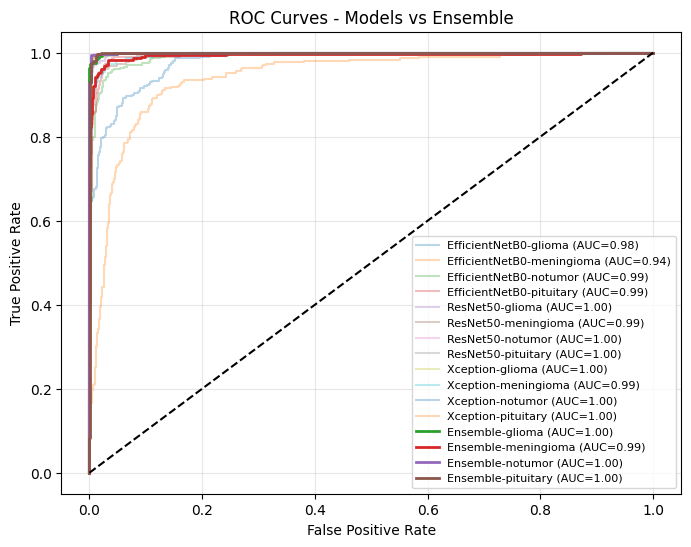

In [ ]:
plt.figure(figsize=(8,6))

# Individual models
for model, name in zip([final_model, resnet_model, xception_model],
                       ["EfficientNetB0", "ResNet50", "Xception"]):
    preds = model.predict(test_generator, verbose=0)
    for i, label in enumerate(labels):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], preds[:, i])
        auc_score = auc(fpr, tpr)
        plt.plot(fpr, tpr, alpha=0.3, label=f"{name}-{label} (AUC={auc_score:.2f})")

# Ensemble
for i, label in enumerate(labels):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], weighted_preds[:, i])
    auc_score = auc(fpr, tpr)
    plt.plot(fpr, tpr, linewidth=2, label=f"Ensemble-{label} (AUC={auc_score:.2f})")

plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Models vs Ensemble")
plt.legend(fontsize=8, loc="lower right")
plt.grid(alpha=0.3)
plt.show()


###### **16.Test Accuracy Comparison (All Models vs Ensemble)**

In [ ]:
def get_test_accuracy(model, test_gen):
    loss, acc = model.evaluate(test_gen, verbose=0)
    return acc

test_acc_cnn = get_test_accuracy(model, test_generator)
test_acc_eff = get_test_accuracy(final_model, test_generator)
test_acc_res = get_test_accuracy(resnet_model, test_generator)
test_acc_xcp = get_test_accuracy(xception_model, test_generator)


/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


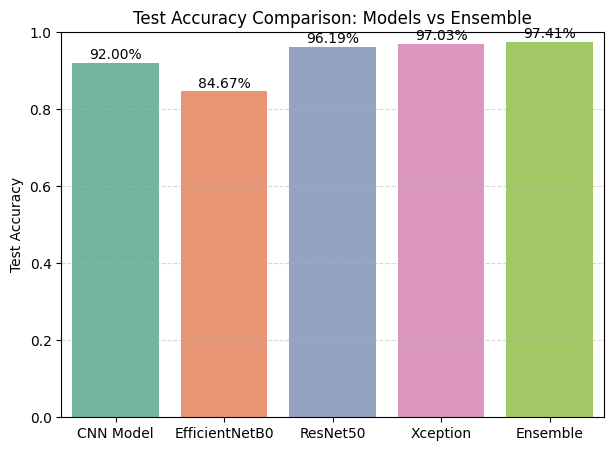

In [ ]:
ensemble_test_acc = accuracy_score(y_true, y_pred)

labels_models = ["CNN Model","EfficientNetB0", "ResNet50", "Xception", "Ensemble"]
test_accuracies = [test_acc_cnn,test_acc_eff, test_acc_res, test_acc_xcp, ensemble_test_acc]

plt.figure(figsize=(7,5))
sns.barplot(x=labels_models, y=test_accuracies, palette="Set2")
for i, v in enumerate(test_accuracies):
    plt.text(i, v+0.01, f"{v:.2%}", ha='center', fontsize=10)
plt.title("Test Accuracy Comparison: Models vs Ensemble")
plt.ylabel("Test Accuracy")
plt.ylim(0,1)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()